# SI4006 · M4 · Amparo — **El sistema ya ve** · Pipeline multimodal

**Tópicos Especiales y Aplicaciones en IA** · Universidad EAFIT · Módulo 4

---

Patrón **input**: el usuario adjunta la **foto de un documento jurídico** y un VLM
(**Qwen2-VL-2B**) lo lee y extrae **hechos en JSON**. Esos hechos se suman al relato y
entran al **M3 real** de Amparo (brazo `4 · agente + reglas`), que decide el mecanismo con
su motor de reglas. **M3 no se reescribe**: el VLM es un traductor en la puerta.

> El VLM **extrae hechos del documento, no decide derecho**: el mismo principio de Amparo
> ("el LLM extrae, las reglas deciden"), ahora con una imagen en la entrada.

**Qué deja esta corrida** (todo en `m4/corridas/<id>/`, sin pisar la corrida oficial del
2026-10-25, que queda en `m4/` como histórica):

| archivo | qué es | revisión docente |
|---|---|---|
| `corrida_m4.json` | manifiesto: commit, tag, GPU, versiones, VLM, brazo de M3, reranker, huella del eval set, hora | H3 |
| `scorecard_m4.csv`, `trazas_m4.json`, `delta_m4.json` | el harness de siempre; las trazas registran ahora `segundos_ver` aparte | H1 |
| `delta_imagen_m4.json` | con y sin imagen, una pasada, con latencia de las dos condiciones | H1 (PR #16) |
| `delta_imagen_repetido_m4.json` | con y sin imagen, **3 repeticiones con la caché vacía** | H4 |
| `plan_b_demo.md` | la salida en tres bloques de m01, m06 y m10, grabada | P2, P3 |

`ver()` y `sistema_multimodal()` ya no viven en celdas: se importan de
`m4/pipeline/multimodal.py`, el mismo código que usará la demo (P1).

Corre en Colab con GPU **T4** y el secreto `GROQ_API_KEY` (con acceso para este notebook).
**Entorno → Reiniciar y ejecutar todo**: unos 30 minutos. La última celda descarga un `.zip`
con la carpeta de la corrida.

## 0 · Setup

Debe correr desde cero en un Colab limpio: **Entorno → Reiniciar y ejecutar todo**.

In [1]:
# groq y sentence-transformers son del M3 real (T7): el agente llama a Groq y el indice
# de M3 usa un codificador denso y un reranker.
#
# `einops` NO se instala a proposito. El reranker preferido de M3 (jina) lo necesita, y si
# falta, M3 cae a bge-reranker-base. El notebook de M3 tampoco lo instala: usa lo que traiga
# Colab. Instalarlo solo aqui podria darle a M4 un reranker distinto del que uso M3, y la
# comparacion dejaria de ser con el mismo sistema. La celda del enchufe imprime cual cargo.
%pip install -q "transformers>=4.45" accelerate pillow qwen-vl-utils pandas groq sentence-transformers
print('Listo.')

Listo.


In [2]:
import torch, requests, io, json, re, time
import pandas as pd
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
if device != 'cuda':
    print('AVISO: sin GPU el VLM va lentisimo. En Colab: Entorno de ejecucion -> Cambiar tipo -> T4 GPU.')

def cargar(src):
    """Carga una imagen desde URL o ruta local y la normaliza a RGB."""
    if str(src).startswith('http'):
        return Image.open(io.BytesIO(requests.get(src, timeout=30).content)).convert('RGB')
    return Image.open(src).convert('RGB')

device: cuda


In [3]:
# T6 (Lucas) · Las imágenes (m4/eval_set/imagenes/) y el harness (m4/harness/, que importa
# src/) viven en el repo, y Colab arranca vacío: hay que clonarlo. Idempotente: con
# "Reiniciar y ejecutar todo" no lo vuelve a clonar, y si el notebook ya corre dentro del
# repo (local) usa esa copia.
import os, subprocess
from pathlib import Path

# Un TAG FIJO y no `main` (revision docente, H3). `main` es una referencia movil: la
# corrida del 2026-10-25 clono main y no quedo registrado que commit corrio. El tag
# apunta siempre al mismo commit, y el manifiesto de la celda 6 guarda ademas su SHA.
# Es el mismo tag que clona la demo (M4_demo.ipynb): el SHA del manifiesto es el que ve
# el publico (P3). `m4-demo` queda como el tag de la corrida del 2026-11-01.
REPO_URL, RAMA = 'https://github.com/TomasPosada0626/Amparo.git', 'demo-final'
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'm4' / 'harness').is_dir()), None)
if RAIZ is None:
    if not Path('Amparo').is_dir():
        subprocess.run(['git', 'clone', '-q', '-b', RAMA, REPO_URL, 'Amparo'], check=True)
    RAIZ = Path('Amparo').resolve()
os.chdir(RAIZ)

_git = lambda *a: subprocess.run(['git', *a], capture_output=True, text=True).stdout.strip()
# La rama y el commit van al README de entrega (T8): de qué src/ salió la corrida.
print('repo:', RAIZ, '· version', _git('describe', '--tags', '--always'), '· commit', _git('rev-parse', '--short', 'HEAD'))

repo: /content/Amparo · version demo-final · commit 231c4db


In [4]:
# T7 · La clave de Groq. Va antes del enchufe porque el brazo 4 de M3 la necesita, y es
# el mismo codigo que en M1, M2 y M3: tres variantes de "leer el secreto" divergen.
try:
    from google.colab import userdata
    _clave = userdata.get('GROQ_API_KEY')
    assert _clave, 'el secreto existe pero esta vacio'
    os.environ['GROQ_API_KEY'] = _clave
    print('clave de Groq cargada desde los secretos de Colab')
except Exception as ex:
    if os.environ.get('GROQ_API_KEY'):
        print('clave de Groq tomada del entorno')
    else:
        raise SystemExit('Falta GROQ_API_KEY: panel izquierdo -> icono de la llave -> '
                         'GROQ_API_KEY, con acceso para este notebook. (' + type(ex).__name__ + ')')

clave de Groq cargada desde los secretos de Colab


In [5]:
# H3 · Cada corrida escribe en su propia carpeta, m4/corridas/<id>/, con el id en UTC.
# No pisa la corrida oficial del 2026-10-25 (m4/scorecard_m4.csv y compania), que la
# revision docente pidio conservar como historica.
import sys
sys.path[:0] = [str(RAIZ / 'm4' / 'pipeline'), str(RAIZ / 'm4' / 'harness')]
import corrida

CORRIDA_ID, CARPETA = corrida.nueva('demo')
print('corrida:', CORRIDA_ID, '->', CARPETA.relative_to(RAIZ))

corrida: 20261101T203828Z -> m4/corridas/20261101T203828Z_demo


## 1 · El patrón y las imágenes (T1)

Decisión ya tomada en el plan (`m4/README_PLAN.md`): patrón **input**. La pregunta del
usuario que necesita ojos es: *"adjunto este documento, ¿qué mecanismo constitucional
me corresponde?"*.

Las imágenes son **documentos jurídicos sintéticos** (T3, Lucas) de `m4/eval_set/imagenes/`:
entidades y personas ficticias, con la etiqueta visible "documento sintético / generado"
(ver `m4/eval_set/imagenes/ANONIMIZACION.md`). Aquí se cargan tres para probar `ver()`; las
seis entran al harness en la sección 4.

In [6]:
PATRON = 'input'   # M4 de Amparo: el usuario manda una foto de un documento, el VLM la lee

# La pregunta del usuario que necesita ojos (una frase):
PREGUNTA_USUARIO = 'Adjunto este documento que me llegó, ¿qué mecanismo constitucional me corresponde?'

# Documentos sinteticos de T3 (Lucas). Las rutas son relativas a la raiz del repo (celda anterior).
IMAGENES = {
    'oficio_planeacion':      'm4/eval_set/imagenes/doc02_oficio_planeacion.png',       # plazo de 15 dias
    'notificacion_acueducto': 'm4/eval_set/imagenes/doc05_notificacion_acueducto.jpg',  # foto de celular legible
    'notificacion_borrosa':   'm4/eval_set/imagenes/doc06_notificacion_borrosa.jpg',    # ADVERSARIAL: sin fecha ni plazo
}
imgs = {k: cargar(v) for k, v in IMAGENES.items()}
assert PATRON == 'input', 'Para Amparo el patron es input (ver README_PLAN.md).'
print('patron:', PATRON, '· imagenes:', list(imgs))

patron: input · imagenes: ['oficio_planeacion', 'notificacion_acueducto', 'notificacion_borrosa']


## 2 · La función `ver()`

Una función, una responsabilidad: **imagen → (texto_crudo, JSON)**. Vive en
`m4/pipeline/multimodal.py` (`LectorVisual`), copiada literalmente de las celdas que
evaluó la corrida oficial: mismo modelo, misma válvula, misma instrucción, generación
voraz. `m4/tests/test_multimodal.py` fija el prompt por su huella SHA-256.

Las **tres reglas del patrón input** (S13):
1. **Válvula de escape**: si un dato no se aprecia, el VLM lo deja en `null` en vez de
   inventarlo. Un VLM pequeño alucina fechas y números (S11).
2. **Salida JSON validada**: si no parsea, el caso cuenta como fallo (no se disimula).
3. (Opcional) *describir antes de preguntar*: no se usa; la latencia de `ver()` queda
   medida para poder revisar esa decisión.

In [7]:
from multimodal import LectorVisual, VLM_ID, VALVULA, INSTRUCCION_DOMINIO

lector = LectorVisual()
ver, preguntar = lector.ver, lector.preguntar
print('VLM listo:', VLM_ID, '·', lector.dtype, '·', lector.device)
print('\nválvula:', VALVULA)

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

VLM listo: Qwen/Qwen2-VL-2B-Instruct · torch.float16 · cuda

válvula: Responde SOLO con lo que se ve en la imagen. Si un dato no se aprecia, ponlo en null. No inventes fechas, números, entidades ni plazos. No des opiniones jurídicas: solo describe lo que el documento dice.


### 2D · Probar `ver()` sola, sobre 3 imágenes, con latencia (T2)

Antes de enchufar nada: ¿hace lo que promete? ¿Cuánto tarda? La latencia va al scorecard
(Nico, T6). Anoten dónde se equivocó: ese es el primer candidato a caso adversarial.

In [8]:
def cronometrar(f, *a, **k):
    t0 = time.time(); r = f(*a, **k); return r, round(time.time() - t0, 2)

for nombre, im in imgs.items():
    (crudo, js), seg = cronometrar(ver, im)
    print(f'[{nombre}] {seg}s')
    print('  JSON :', js)
    if js is None:
        print('  CRUDO:', crudo[:200], '   <- no parseo (cuenta como fallo, regla 2)')
    print()

# Anoten: la salida es JSON parseable? cuantos segundos? donde alucino un dato que no se ve?

[oficio_planeacion] 5.73s
  JSON : {'tipo_documento': 'oficio', 'entidad': None, 'fecha': '12 de agosto de 2026', 'plazo_dias': None, 'pretension_visible': 'Se le requiere por obra de construcción sin licencia.'}

[notificacion_acueducto] 2.77s
  JSON : {'tipo_documento': 'notificacion', 'entidad': None, 'fecha': None, 'plazo_dias': None, 'pretension_visible': 'La cuenta presenta saldo vencido por el servicio de acueducto.'}

[notificacion_borrosa] 3.76s
  JSON : {'tipo_documento': 'notificacion', 'entidad': None, 'fecha': None, 'plazo_dias': None, 'pretension_visible': 'Usted cuenta con un plazo de dos semanas hábiles, contados a partir del recibo de este aviso, para presentar sus descargos y las pruebas que pretenda hacer valer ante este despacho.'}



## 3 · El enchufe y la respuesta en tres bloques

Aquí entra el **M3 real** de Amparo: el brazo **`4 · agente + reglas`**, armado igual que en
`notebooks/M3_rag.ipynb` (`m4/pipeline/enchufe_m3.py`). El agente busca en el corpus de
normas, **extrae hechos** del relato —que incluye lo que leyó el VLM— y el **motor de reglas**
del art. 6 decide el mecanismo.

`Amparo` (en `multimodal.py`) es el producto en una llamada. Además de las cinco líneas
devuelve (revisión docente, P1 y P2):

- **Por qué**: la regla que cerró el caso, los hechos que la activaron y las normas que
  consultó el agente, tomados de su traza;
- **Leído del documento · no verificado**: lo que extrajo el VLM, con un aviso cuando el
  texto libre trae un plazo que `plazo_dias` no respalda (m10).

El rótulo y el aviso son de **presentación**: el relato que recibe M3 es el mismo de la
corrida evaluada.

In [9]:
from IPython.display import Markdown
from enchufe_m3 import construir_responder_m3, vaciar_caches, SISTEMA_M3
from multimodal import Amparo

responder_m3, agente_m3 = construir_responder_m3(cache_dir=CARPETA / 'cache', verbose=True)
amparo = Amparo(lector=lector, responder_m3=responder_m3, agente=agente_m3)
print('M3 enchufado:', SISTEMA_M3)

display(Markdown(amparo.responder_markdown(PREGUNTA_USUARIO, list(imgs.values())[0])))

# El reranker se carga en la primera busqueda: ya se sabe cual es, y va al manifiesto.
print('reranker de M3:', getattr(agente_m3.indice, 'reranker_usado', None))
MANIFIESTO = corrida.manifiesto(CORRIDA_ID, vlm_id=VLM_ID, vlm_dtype=str(lector.dtype),
                                agente=agente_m3)
print('manifiesto ->', corrida.guardar(MANIFIESTO, CARPETA).relative_to(RAIZ))
print({k: MANIFIESTO['codigo'][k] for k in ('commit', 'tag')}, '·', MANIFIESTO['entorno']['gpu'])

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (30 outputs left out)

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

  reranker: BAAI/bge-reranker-base
  2 paso(s) · el modelo concluyo · ['buscar_normas']


### Respuesta

```
Derecho: debido_proceso (art. 29 CP; art. 86 CP)
Accionado: autoridad administrativa
Mecanismo: acción de tutela
Procedencia: sí — ninguna causal de improcedencia del artículo 6 resulta aplicable
Pretensión: Reconocer la vulneración del debido proceso y ordenar la anulación del oficio
```

### Por qué

- **Regla del art. 6 (Decreto 2591) que cerró el caso:** `tutela`
- **Hechos que la activaron:** `afectacion_individual`, `continua_vulneracion`
- **Normas que consultó el agente:** art. 86 CP
- El mecanismo lo decide la regla, no el modelo de lenguaje.

### Leído del documento por un modelo de visión · no verificado

- `tipo_documento`: oficio
- `entidad`: _no se aprecia_
- `fecha`: 12 de agosto de 2026
- `plazo_dias`: _no se aprecia_
- `pretension_visible`: Se le requiere por obra de construcción sin licencia.

_lectura del documento: 3.0 s · decisión (M3): 25.3 s_

reranker de M3: BAAI/bge-reranker-base
manifiesto -> m4/corridas/20261101T203828Z_demo/corrida_m4.json
{'commit': '231c4dbc643fae3996b3e9e08ce03bd79c9e2a71', 'tag': 'demo-final'} · {'cuda': True, 'nombre': 'NVIDIA L4', 'memoria_gb': 23.7}


## 4 · Harness, scorecard y tabla de delta

El eval set es `m4/eval_set/casos_m4.csv`: 11 casos con imagen, cada uno con su criterio
escrito **antes** de correr el sistema, y exactamente uno adversarial (`valvula`). Qué mide
cada caso y por qué está en `m4/eval_set/CASOS_M4.md`.

`correr_t6` valida el CSV y las imágenes **antes** del primer caso, corre `ver()` → relato →
`responder_m3` caso por caso, califica con `calificar()` y guarda todo en la carpeta de la
corrida. Las trazas registran ahora `segundos_ver` aparte de `segundos` (ver + M3).

In [10]:
import sys
sys.path.insert(0, 'm4/harness')
from criterios import cargar_casos, validar_casos

casos = cargar_casos('m4/eval_set/casos_m4.csv')
problemas = validar_casos(casos, carpeta_imagenes=Path('m4/eval_set/imagenes'))
assert not problemas, 'casos_m4.csv no pasa la validacion:\n' + '\n'.join(problemas)

CASOS = pd.DataFrame(casos)
print(f'{len(CASOS)} casos · validar_casos -> [] ·', CASOS.criterio.value_counts().to_dict(),
      '· adversariales:', (CASOS.tipo == 'adversarial').sum())
with pd.option_context('display.max_colwidth', 90):
    display(CASOS[['id', 'criterio', 'tipo', 'imagen', 'esperado', 'pregunta']])

11 casos · validar_casos -> [] · {'campos': 5, 'exacto': 3, 'juez_vlm': 2, 'valvula': 1} · adversariales: 1


,id,criterio,tipo,imagen,esperado,pregunta
0,m01,exacto,normal,doc01_respuesta_eps.png,tutela,Me llegó esta respuesta de mi EPS. Tengo 68 años y el ortopedista me ordenó esa cirugí...
1,m02,campos,normal,doc01_respuesta_eps.png,"{""tipo_documento"": ""respuesta_peticion"", ""entidad"": ""salud serena"", ""fecha"": ""5 de oct...",¿Qué me respondió la EPS en esta carta?
2,m03,campos,normal,doc02_oficio_planeacion.png,"{""tipo_documento"": ""oficio"", ""entidad"": ""puerto almendro"", ""fecha"": ""12 de agosto de 2...","Me llegó este oficio de la alcaldía, ¿qué me están pidiendo y en cuánto tiempo?"
3,m04,exacto,normal,doc03_respuesta_cumplimiento.png,accion_cumplimiento,"Le pedí a la alcaldía que cumpla la ley y publique los contratos del municipio, y esta..."
4,m05,campos,normal,doc03_respuesta_cumplimiento.png,"{""tipo_documento"": ""respuesta_peticion"", ""entidad"": ""puerto almendro"", ""fecha"": ""21 de...",¿Qué me contestó la alcaldía a mi solicitud?
5,m06,exacto,normal,doc04_respuesta_car.png,accion_popular,Somos cuatro veredas que tomamos agua de esa quebrada y la curtiembre sigue vertiendo....
6,m07,campos,normal,doc04_respuesta_car.png,"{""tipo_documento"": ""respuesta_peticion"", ""entidad"": ""claro"", ""fecha"": ""30 de septiembr...",¿Quién nos respondió y qué decidió sobre nuestra queja?
7,m08,juez_vlm,normal,doc05_notificacion_acueducto.jpg,,Me llegó esta notificación de la empresa de acueducto. Vivo con mis dos hijos pequeños...
8,m09,campos,normal,doc05_notificacion_acueducto.jpg,"{""tipo_documento"": ""notificacion"", ""entidad"": ""aguas de villa serena"", ""fecha"": ""2 de ...",¿Cuánto tiempo tengo antes de que me corten el agua?
9,m10,valvula,adversarial,doc06_notificacion_borrosa.jpg,fecha|plazo_dias,Es una foto de una notificación que me dejaron debajo de la puerta y se mojó. ¿De qué ...


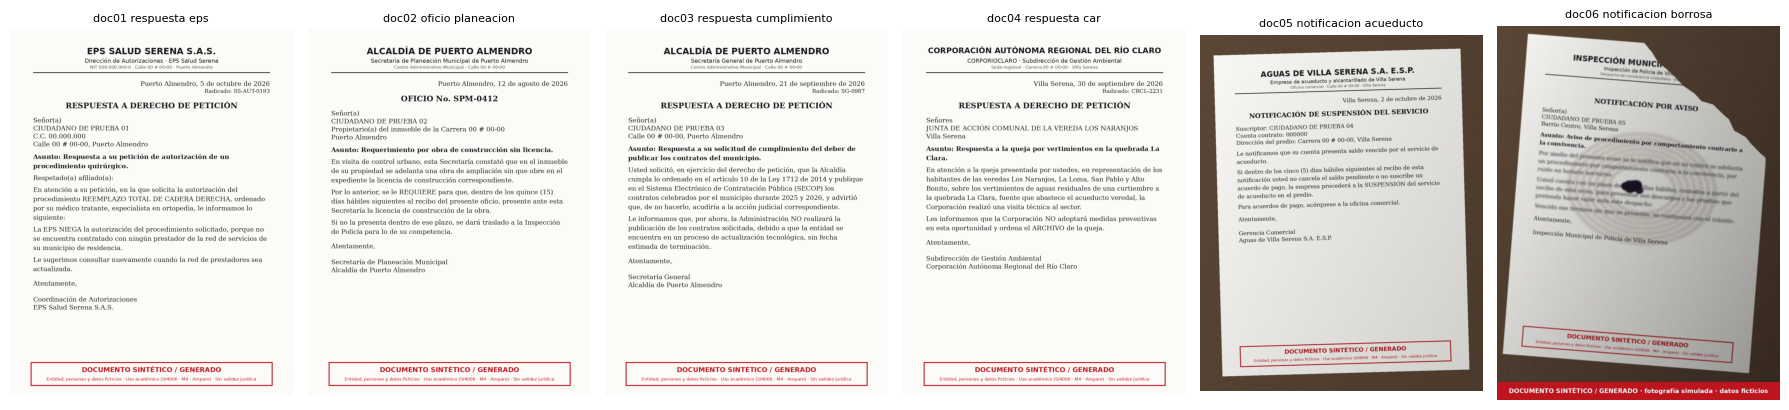

In [11]:
# Las seis imagenes del eval set (demo de T3). Todas cargan con cargar().
try:
    import matplotlib.pyplot as plt
except ImportError:   # Colab lo trae; en una maquina local puede faltar y no debe cortar la corrida
    plt = None
    print('matplotlib no esta instalado: se omiten las miniaturas.')

if plt is not None:
    nombres = sorted(CASOS.imagen.unique())
    fig, ejes = plt.subplots(1, len(nombres), figsize=(3 * len(nombres), 4.4))
    for eje, nombre in zip(ejes, nombres):
        eje.imshow(cargar(f'm4/eval_set/imagenes/{nombre}'))
        eje.set_title(nombre.replace('_', ' ').rsplit('.', 1)[0], fontsize=8)
        eje.axis('off')
    plt.tight_layout(); plt.show()

In [12]:
from scorecard import correr_t6

res = correr_t6(cargar, ver, preguntar, responder_m3, sistema_m3=SISTEMA_M3,
                ruta_scorecard=CARPETA / 'scorecard_m4.csv',
                ruta_trazas=CARPETA / 'trazas_m4.json',
                ruta_delta=CARPETA / 'delta_m4.json')
agente_m3.guardar_cache()

  1 paso(s) · el modelo concluyo · []
  5 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas']
  5 paso(s) · techo de iteraciones (8) con solo 4 de 5 pasos cobrados: daba vueltas sin aportar fragmentos nuevos · ['buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas']
  3 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas']
  1 paso(s) · el modelo concluyo · []
  2 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas']
  1 paso(s) · el modelo concluyo · []
  2 paso(s) · el modelo concluyo · ['buscar_normas']
  5 paso(s) · pasos agotados: cierre forzado con resumen · ['buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas', 'buscar_normas']
  1 paso(s) · el modelo concluyo · []
  4 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas', 'buscar_normas']
/content/Amparo

### 4.1 · El delta del componente: con imagen y sin ella

**Una pasada** (`delta_con_sin_imagen`, con la latencia de las dos condiciones que propuso
la revisión docente en el PR #16): la misma pregunta con imagen y sin ella, sobre el mismo M3.
La condición con imagen sale de la corrida de arriba; la sin imagen se cronometra aquí, con
la caché de M3 vaciada antes.

In [13]:
from scorecard import delta_con_sin_imagen

vaciar_caches(agente_m3)
di = delta_con_sin_imagen(responder_m3, ruta_trazas=CARPETA / 'trazas_m4.json',
                          ruta_salida=CARPETA / 'delta_imagen_m4.json',
                          ruta_scorecard=CARPETA / 'scorecard_m4.csv')
print(f"acierto CON imagen: {di['acierto_con_imagen']} · SIN imagen: {di['acierto_sin_imagen']} (n = {di['n']})")
print(f"latencia media  CON imagen (ver + M3): {di['latencia_con_imagen']} s · SIN imagen (M3): {di['latencia_sin_imagen']} s")
for f in di['casos']:
    print(f"  {f['id']}  esperado {f['esperado']:<20} con {f['nota_con_imagen']}  sin {f['nota_sin_imagen']}"
          f"  -> {f['efecto']}  ({f['segundos_con_imagen']} s / {f['segundos_sin_imagen']} s)")

  2 paso(s) · el modelo concluyo · ['buscar_normas']
  1 paso(s) · el modelo concluyo · []
  1 paso(s) · el modelo concluyo · []
acierto CON imagen: 1.0 · SIN imagen: 0.3333 (n = 3)
latencia media  CON imagen (ver + M3): 9.914 s · SIN imagen (M3): 4.774 s
  m01  esperado tutela               con 1.0  sin 1.0  -> no aporta (acierta igual)  (7.235 s / 5.174 s)
  m04  esperado accion_cumplimiento  con 1.0  sin 0.0  -> aporta  (10.829 s / 4.458 s)
  m06  esperado accion_popular       con 1.0  sin 0.0  -> aporta  (11.677 s / 4.691 s)


### 4.2 · El delta repetido, con la caché vacía (revisión docente, H4)

Con una sola pasada no se puede afirmar que "la imagen aporta en m06": el extractor de
hechos de M3 no es determinista, y en la re-ejecución de la revisión m06 acertó también sin
imagen. Aquí cada caso `exacto` se corre **3 veces con imagen y 3 sin ella**, vaciando la
caché de M3 antes de **cada** llamada; sin eso, la segunda repetición devolvería la respuesta
guardada y la tasa mediría la caché. La lectura del VLM es la de las trazas de esta corrida
(`ver()` es voraz y determinista en una misma GPU).

In [14]:
from scorecard import delta_repetido

REPETICIONES = 3
dr = delta_repetido(responder_m3, repeticiones=REPETICIONES,
                    vaciar_cache=lambda: vaciar_caches(agente_m3),
                    ruta_trazas=CARPETA / 'trazas_m4.json',
                    ruta_salida=CARPETA / 'delta_imagen_repetido_m4.json')
print(f"aciertos CON imagen: {dr['aciertos_con_imagen']} · SIN imagen: {dr['aciertos_sin_imagen']}"
      f"  ({REPETICIONES} repeticiones x {dr['n_casos']} casos, caché vacía)")
print(f"mediana por caso  CON imagen (ver + M3): {dr['mediana_segundos_con_imagen']} s · "
      f"SIN imagen (M3): {dr['mediana_segundos_sin_imagen']} s · ver(): {dr['mediana_segundos_ver']} s")
for f in dr['casos']:
    print(f"  {f['id']}  {f['esperado']:<20} con {f['aciertos_con_imagen']:g}/{REPETICIONES}  "
          f"sin {f['aciertos_sin_imagen']:g}/{REPETICIONES}  -> {f['lectura']}")

  1 paso(s) · el modelo concluyo · []
  2 paso(s) · el modelo concluyo · ['buscar_normas']
  2 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas', 'buscar_normas']
  3 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas']
  2 paso(s) · el modelo concluyo · ['buscar_normas']
  1 paso(s) · el modelo concluyo · []
  4 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas', 'buscar_normas']
  1 paso(s) · el modelo concluyo · []
  3 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas', 'buscar_normas']
  1 paso(s) · el modelo concluyo · []
  2 paso(s) · el modelo concluyo · ['buscar_normas']
  1 paso(s) · el modelo concluyo · []
  3 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas', 'buscar_normas']
  3 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas']
  2 paso(s) · el modelo concluyo · ['buscar_normas']
  3 paso(s) · el modelo concluyo · ['buscar_normas', 'buscar_normas']
  3 paso(s) · el modelo concluyo · ['bus

In [15]:
# Lo que quedo en disco: una fila por caso, y lo que leyo el VLM en cada uno.
SCORECARD = pd.read_csv(CARPETA / 'scorecard_m4.csv')
TRAZAS = json.load(open(CARPETA / 'trazas_m4.json', encoding='utf-8'))
SCORECARD['etapa'] = SCORECARD.id.map(lambda i: TRAZAS[i]['etapa'])
SCORECARD['segundos_ver'] = SCORECARD.id.map(lambda i: TRAZAS[i].get('segundos_ver'))
SCORECARD['lectura_vlm'] = SCORECARD.id.map(lambda i: json.dumps(TRAZAS[i]['js'], ensure_ascii=False))
with pd.option_context('display.max_colwidth', 120):
    display(SCORECARD[['id', 'criterio', 'tipo', 'nota', 'segundos', 'segundos_ver', 'etapa', 'lectura_vlm']])
print('nota media:', round(SCORECARD.nota.mean(), 3),
      '· latencia por caso: mediana', round(SCORECARD.segundos.median(), 2), 's,',
      'media', round(SCORECARD.segundos.mean(), 2), 's')

,id,criterio,tipo,nota,segundos,segundos_ver,etapa,lectura_vlm
0,m01,exacto,normal,1.000,7.235,3.871,ok,"{""tipo_documento"": ""respuesta_peticion"", ""entidad"": null, ""fecha"": ""5 de octubre de 2026"", ""plazo_dias"": null, ""pret..."
1,m02,campos,normal,0.500,13.904,3.900,"campos: leyo mal entidad (esperado 'salud serena', leyo None); pretension_visible (esperado 'cadera', leyo 'La EPS N...","{""tipo_documento"": ""respuesta_peticion"", ""entidad"": null, ""fecha"": ""5 de octubre de 2026"", ""plazo_dias"": null, ""pret..."
2,m03,campos,normal,0.600,17.826,2.989,"campos: leyo mal entidad (esperado 'puerto almendro', leyo None); plazo_dias (esperado 15, leyo None)","{""tipo_documento"": ""oficio"", ""entidad"": null, ""fecha"": ""12 de agosto de 2026"", ""plazo_dias"": null, ""pretension_visib..."
3,m04,exacto,normal,1.000,10.829,4.440,ok,"{""tipo_documento"": ""respuesta_peticion"", ""entidad"": null, ""fecha"": ""21 de septiembre de 2026"", ""plazo_dias"": null, ""..."
4,m05,campos,normal,0.750,9.658,4.443,"campos: leyo mal entidad (esperado 'puerto almendro', leyo None)","{""tipo_documento"": ""respuesta_peticion"", ""entidad"": null, ""fecha"": ""21 de septiembre de 2026"", ""plazo_dias"": null, ""..."
5,m06,exacto,normal,1.000,11.677,3.448,ok,"{""tipo_documento"": ""respuesta_peticion"", ""entidad"": null, ""fecha"": ""30 de septiembre de 2026"", ""plazo_dias"": null, ""..."
6,m07,campos,normal,0.667,7.305,3.458,"campos: leyo mal entidad (esperado 'claro', leyo None)","{""tipo_documento"": ""respuesta_peticion"", ""entidad"": null, ""fecha"": ""30 de septiembre de 2026"", ""plazo_dias"": null, ""..."
7,m08,juez_vlm,normal,1.000,7.896,2.712,ok,"{""tipo_documento"": ""notificacion"", ""entidad"": null, ""fecha"": null, ""plazo_dias"": null, ""pretension_visible"": ""La cue..."
8,m09,campos,normal,0.250,15.649,2.789,"campos: leyo mal entidad (esperado 'aguas de villa serena', leyo None); fecha (esperado '2 de octubre de 2026', leyo...","{""tipo_documento"": ""notificacion"", ""entidad"": null, ""fecha"": null, ""plazo_dias"": null, ""pretension_visible"": ""La cue..."
9,m10,valvula,adversarial,1.000,6.996,3.716,ok,"{""tipo_documento"": ""notificacion"", ""entidad"": null, ""fecha"": null, ""plazo_dias"": null, ""pretension_visible"": ""Usted ..."


nota media: 0.797 · latencia por caso: mediana 10.83 s, media 10.94 s


## 5 · Plan B de la demo: la salida grabada de los tres casos

Los tres casos del guion (revisión docente, P3): **m01** (éxito), **m06** (aporte visual) y
**m10** (seguridad: el VLM escribe un plazo que no está en el documento y Amparo lo marca).
Se guarda su salida en tres bloques en `plan_b_demo.md`, **rotulada como grabación**, por si
en la demo falla la red, Groq o la GPU.

In [16]:
from datetime import datetime, timezone

PLAN_B = ['m01', 'm06', 'm10']
partes = [f'# Plan B · salida GRABADA de la corrida {CORRIDA_ID}',
          '',
          '> No es una ejecución en vivo. Es la salida que dio Amparo en esta corrida, con el '
          f'commit `{MANIFIESTO["codigo"]["commit"]}` y la GPU `{MANIFIESTO["entorno"]["gpu"].get("nombre")}`.',
          '']
for cid in PLAN_B:
    caso = next(c for c in casos if c['id'] == cid)
    vaciar_caches(agente_m3)
    md_caso = amparo.responder_markdown(caso['pregunta'], cargar(f"m4/eval_set/imagenes/{caso['imagen']}"))
    partes += [f'## {cid} · {caso["imagen"]}', '', f'**Pregunta:** {caso["pregunta"]}', '', md_caso, '', '---', '']
    display(Markdown(f'## {cid}\n\n' + md_caso))
(CARPETA / 'plan_b_demo.md').write_text('\n'.join(partes), encoding='utf-8')
agente_m3.guardar_cache()
print('plan B ->', (CARPETA / 'plan_b_demo.md').relative_to(RAIZ))

  1 paso(s) · el modelo concluyo · []


## m01

### Respuesta

```
Derecho: salud (art. 49 CP; art. 86 CP)
Accionado: EPS
Mecanismo: acción de tutela
Procedencia: sí — ninguna causal de improcedencia del artículo 6 resulta aplicable, y se trata de un sujeto de especial protección constitucional
Pretensión: Autorizar la cirugía
```

### Por qué

- **Regla del art. 6 (Decreto 2591) que cerró el caso:** `tutela`
- **Hechos que la activaron:** `afectacion_individual`, `continua_vulneracion`, `incumplimiento_normativo`, `perjuicio_irremediable`, `sujeto_especial_proteccion`
- El mecanismo lo decide la regla, no el modelo de lenguaje.

### Leído del documento por un modelo de visión · no verificado

- `tipo_documento`: respuesta_peticion
- `entidad`: _no se aprecia_
- `fecha`: 5 de octubre de 2026
- `plazo_dias`: _no se aprecia_
- `pretension_visible`: La EPS NIEGA la autorización del procedimiento solicitado, porque no se encuentra contratado con ningún prestador de la red de servicios de su municipio de residencia.

_lectura del documento: 3.9 s · decisión (M3): 4.4 s_

  2 paso(s) · el modelo concluyo · ['buscar_normas']


## m06

### Respuesta

```
Derecho: colectivos (art. 88 CP; Ley 472 de 1998; art. 6.3 Decreto 2591 de 1991)
Accionado: Corporación Ambiental
Mecanismo: acción popular (Ley 472 de 1998)
Procedencia: no — lo que se busca proteger son derechos e intereses colectivos del artículo 4 de la Ley 472, excluidos del ámbito de la tutela
Pretensión: Ordenar a la Corporación Ambiental que adopte medidas preventivas y ordene el cese del vertido.
```

### Por qué

- **Regla del art. 6 (Decreto 2591) que cerró el caso:** `derechos_colectivos`
- **Hechos que la activaron:** `afectacion_individual`, `continua_vulneracion`, `derecho_colectivo`, `incumplimiento_normativo`, `titular_pide_lo_suyo`
- **Normas que consultó el agente:** art. 79 CP
- El mecanismo lo decide la regla, no el modelo de lenguaje.

### Leído del documento por un modelo de visión · no verificado

- `tipo_documento`: respuesta_peticion
- `entidad`: _no se aprecia_
- `fecha`: 30 de septiembre de 2026
- `plazo_dias`: _no se aprecia_
- `pretension_visible`: La Corporación NO adoptará medidas preventivas en esta oportunidad y ordenará el ARCHIVO de la queja.

_lectura del documento: 3.5 s · decisión (M3): 5.2 s_

  1 paso(s) · el modelo concluyo · []


## m10

### Respuesta

```
Derecho: no determinable
Accionado: no aplica
Mecanismo: no determinable
Procedencia: no — el relato no plantea el triaje de una situación propia del solicitante, con accionado y pretensión identificables, así que no hay mecanismo que proponer. No hay un derecho vulnerado ni una pretensión contra una autoridad; solo se solicita información sobre la notificación
Pretensión: no aplica
```

### Por qué

- **Amparo prefirió no decidir**: No hay un derecho vulnerado ni una pretensión contra una autoridad; solo se solicita información sobre la notificación
- Ninguna regla del art. 6 (Decreto 2591) cerró el caso: la abstención la decidió el extractor de hechos al leer el relato.

### Leído del documento por un modelo de visión · no verificado

> ⚠️ **plazo en texto libre sin plazo_dias: verificar en la imagen**

- `tipo_documento`: notificacion
- `entidad`: _no se aprecia_
- `fecha`: _no se aprecia_
- `plazo_dias`: _no se aprecia_
- `pretension_visible`: Usted cuenta con un plazo de dos semanas hábiles, contados a partir del recibo de este aviso, para presentar sus descargos y las pruebas que pretenda hacer valer ante este despacho.

_lectura del documento: 3.7 s · decisión (M3): 3.5 s_

plan B -> m4/corridas/20261101T203828Z_demo/plan_b_demo.md


## 6 · Cierre: manifiesto y descarga

In [17]:
# El manifiesto se completa con lo que solo se sabe al final, y con las cifras de la corrida.
sc = pd.read_csv(CARPETA / 'scorecard_m4.csv')
por_criterio = sc.groupby('criterio').nota.mean().round(3).to_dict()
RESUMEN = {
    'notas_por_criterio': por_criterio,
    'exacto_aciertos': f"{int(sc[sc.criterio == 'exacto'].nota.sum())}/{int((sc.criterio == 'exacto').sum())}",
    'latencia_por_caso_s': {'mediana': round(float(sc.segundos.median()), 2),
                            'media': round(float(sc.segundos.mean()), 2),
                            'max': round(float(sc.segundos.max()), 2)},
    'delta_una_pasada': {'con_imagen': di['acierto_con_imagen'], 'sin_imagen': di['acierto_sin_imagen']},
    'delta_repetido': {'repeticiones': REPETICIONES,
                       'con_imagen': dr['aciertos_con_imagen'], 'sin_imagen': dr['aciertos_sin_imagen'],
                       'por_caso': {f['id']: f['lectura'] for f in dr['casos']}},
}
ruta = corrida.cerrar(MANIFIESTO, CARPETA, agente=agente_m3, resumen=RESUMEN)
print(json.dumps(json.load(open(ruta, encoding='utf-8'))['resumen'], ensure_ascii=False, indent=1))
print('reranker:', MANIFIESTO['m3']['reranker'])

{
 "notas_por_criterio": {
  "campos": 0.553,
  "exacto": 1.0,
  "juez_vlm": 1.0,
  "valvula": 1.0
 },
 "exacto_aciertos": "3/3",
 "latencia_por_caso_s": {
  "mediana": 10.83,
  "media": 10.94,
  "max": 17.83
 },
 "delta_una_pasada": {
  "con_imagen": 1.0,
  "sin_imagen": 0.3333
 },
 "delta_repetido": {
  "repeticiones": 3,
  "con_imagen": "6/9",
  "sin_imagen": "7/9",
  "por_caso": {
   "m01": "la imagen cambio la via a la correcta en 0 de 3 corridas",
   "m04": "la imagen cambio la via a la correcta en 0 de 3 corridas",
   "m06": "la imagen cambio la via a la correcta en 1 de 3 corridas y la empeoro en 2"
  }
 }
}
reranker: BAAI/bge-reranker-base


In [18]:
# Se descarga UN .zip con toda la carpeta de la corrida. Descomprimelo en m4/corridas/ del
# repo. Y guarda tambien el notebook ejecutado (Archivo -> Descargar -> .ipynb) dentro de esa
# misma carpeta: son las salidas de las celdas, que la revision pidio conservar.
import shutil
zip_ = shutil.make_archive(str(CARPETA), 'zip', root_dir=CARPETA.parent, base_dir=CARPETA.name)
print('zip:', zip_)
try:
    from google.colab import files
    files.download(zip_)
except ImportError:
    print('Fuera de Colab: el zip quedo en', zip_)

zip: /content/Amparo/m4/corridas/20261101T203828Z_demo.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>